<a href="https://colab.research.google.com/github/rehanaga86-tech/ML-Activity-2/blob/main/RCA_Activity_1_Linear_Regression_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

df = pd.read_csv('/house_price_dataset_india_12k.csv')

cols = [
    'Super_Area_sqft',
    'Carpet_Area_sqft',
    'BHK',
    'Property_Age_years',
    'Market_Price_INR',
]
df = df[cols].dropna()
print(df.head())

   Super_Area_sqft  Carpet_Area_sqft  BHK  Property_Age_years  \
0            957.3             809.1    3                   8   
1            883.3             711.7    2                  13   
2           1331.5            1087.1    3                   7   
3            997.6             801.0    3                  10   
4            967.6             707.6    2                   6   

   Market_Price_INR  
0           7736451  
1           5771877  
2          14688106  
3          19094254  
4           7592420  


In [ ]:
small = df[['Super_Area_sqft', 'Property_Age_years', 'Market_Price_INR']].head(4)
print(small)

X_small = np.column_stack(
    [np.ones(4), small['Super_Area_sqft'], small['Property_Age_years']]
)
y_small = small['Market_Price_INR'].values
b_hand = np.linalg.inv(X_small.T @ X_small) @ (X_small.T @ y_small)
print('Intercept, b1 (Area), b2 (Age):', b_hand)

   Super_Area_sqft  Property_Age_years  Market_Price_INR
0            957.3                   8           7736451
1            883.3                  13           5771877
2           1331.5                   7          14688106
3            997.6                  10          19094254
Intercept, b1 (Area), b2 (Age): [-2995027.98805566    14756.02439686   -59405.13093077]


In [ ]:
y = df['Market_Price_INR']
X1 = sm.add_constant(df[['Super_Area_sqft']])
m1 = sm.OLS(y, X1).fit()
features = ['Super_Area_sqft', 'Carpet_Area_sqft', 'BHK', 'Property_Age_years']
X_full = sm.add_constant(df[features])
m_full = sm.OLS(y, X_full).fit()

print(m_full.params)

const                -2.048470e+06
Super_Area_sqft       1.129598e+04
Carpet_Area_sqft     -7.715971e+02
BHK                   8.602566e+05
Property_Age_years   -7.459792e+04
dtype: float64


In [ ]:
for i, col in enumerate(features, start=1):
  vif = variance_inflation_factor(X_full.values, i)
  print(f'{col}: VIF = {vif:.2f}')

Super_Area_sqft: VIF = 29.23
Carpet_Area_sqft: VIF = 21.81
BHK: VIF = 8.21
Property_Age_years: VIF = 1.01


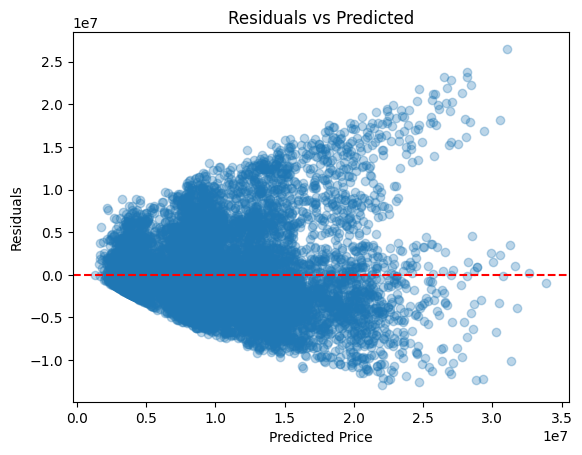

In [ ]:
pred_full = m_full.predict(X_full)
residuals = y - pred_full

plt.scatter(pred_full, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Price')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.show()

In [ ]:
def score_model(model, X_mat, name):
  pred = model.predict(X_mat)
  n = len(y)
  p = X_mat.shape[1] - 1

  mae = mean_absolute_error(y, pred)
  rmse = np.sqrt(mean_squared_error(y, pred))
  r2 = r2_score(y, pred)
  adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

  print(
      f'{name} -> MAE: {mae:,.0f} | RMSE: {rmse:,.0f} | R2: {r2:.4f} | Adj'
      f' R2: {adj_r2:.4f}'
  )


score_model(m1, X1, '1-Feature Model')
score_model(m_full, X_full, 'Full Model')

1-Feature Model -> MAE: 3,455,226 | RMSE: 4,627,742 | R2: 0.5240 | Adj R2: 0.5239
Full Model -> MAE: 3,434,663 | RMSE: 4,600,906 | R2: 0.5295 | Adj R2: 0.5293


In [ ]:
new_house = [
    1.0,
    1400,
    1050,
    3,
    4,
]
pred_one = m_full.predict(new_house)[0]
print(f'Predicted Price: ₹{pred_one:,.2f}')

Predicted Price: ₹15,238,104.18
